In [13]:
import http.client
import time
import urllib.error

import numpy as np
import matplotlib.pyplot as plt

# provides access to FITS files
# a standard format for storing astronomical data, including images and tables
# source: https://docs.astropy.org/en/stable/io/fits/index.html
from astropy.io import fits

# describes transformations between different coordinate sets
# can be used to convert from pixel coordinates to world coordinates and vice versa
# source: https://docs.astropy.org/en/latest/wcs/index.html
from astropy.wcs import WCS

# tools for working with tabular data using an interface similar to numpy
# i.e. structured arrays
# source: https://docs.astropy.org/en/stable/table/index.html
from astropy.table import Table

# helps us account for physical quantities
# source: https://docs.astropy.org/en/stable/units/index.html
from astropy import units as u

# class that provides a way to represent and manipulate celestial coordinates
# and convert between coordinate systems
from astropy.coordinates import SkyCoord

# takes time
from astropy.time import Time

from astropy.visualization import simple_norm

# IRSA queries is a module which "provides access to the public astrophysics catalogs, 
# images, and spectra curated by the NASA/IPAC Infrared Science Archive (IRSA) at Caltech"
# source: https://docs.astropy.org/projects/astroquery/en/latest/ipac/irsa/irsa.html
from astroquery.ipac.irsa import Irsa

# web framework for astronomical data access and visualization, developed at Caltech
# source: https://caltech-ipac.github.io/firefly_client/
from firefly_client import FireflyClient

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

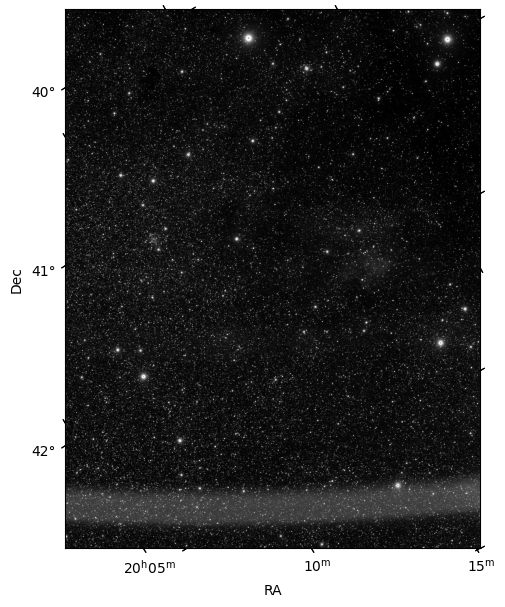

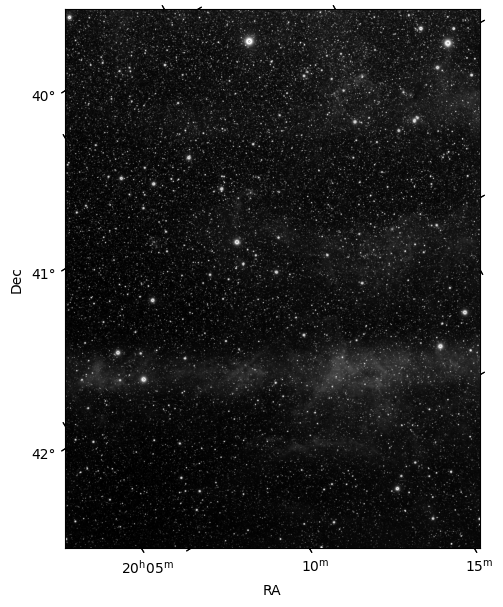

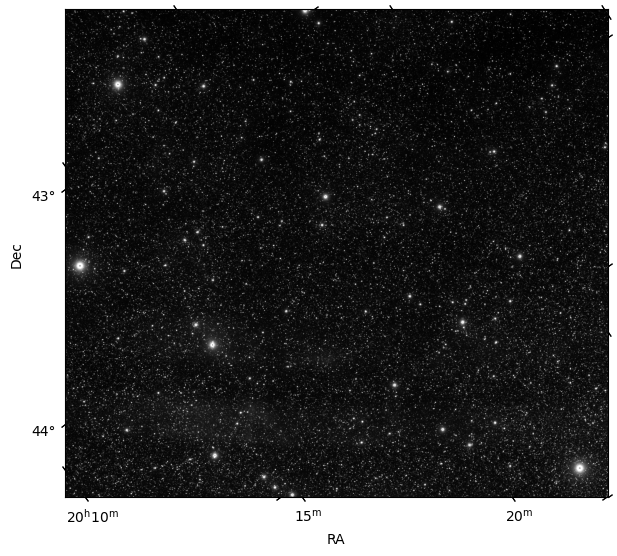

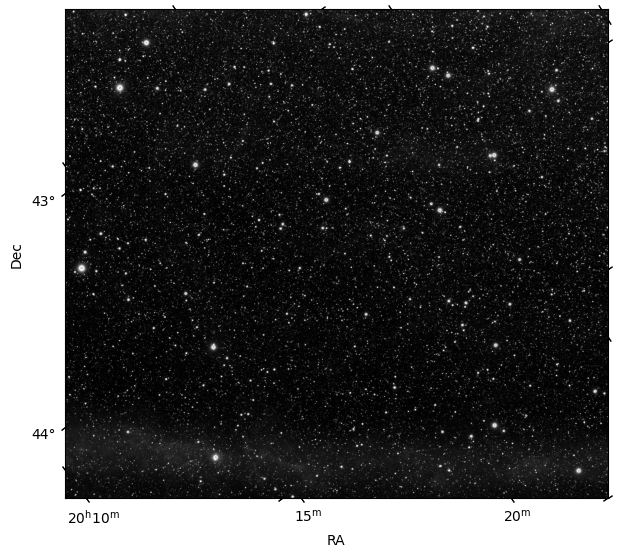

KeyboardInterrupt: 

In [ ]:
def data_pull(ra, dec, fov_val, date1, date2):

    '''
    This function pulls data from IRSA SIA collections for a given RA and Dec, from ALL available data.
    
    User inputs: ra [degrees], dec [degrees], fov_val [degrees]

    This function searches within 1 arcsecond of the given ra and dec, pulling all images that overlap
    with the given parameters.

    fov_val - field of view that that the user wants to zoom in on. Cannot be larger
    than the field of view of the SPHEREx images. 

    IF fov_val exceeds the field of view of the SPHEREx images, the entire image will be displayed, but
    the field of view will not be any larger (i.e. you can't zoom out, only in)

    date1 and date2 - the range of dates that the user wants to search for images.

    Images at the specified coordinates are displayed with the specified field of view.

    Returns: date_observed_list, detector_list

    date_observed_list - list of dates that the images were observed at the specified coordinates
    detector_list - list of detectors that captured the images at the specified coordinates
    
    '''

    ra_deg = ra
    dec_deg = dec
    fov = fov_val * u.deg
    

    coord = SkyCoord(ra_deg, dec_deg, unit='deg')
    search_radius = 1 * u.arcsec  # taking the search radius to be 1 arcsecond

    # Here we prompt IRSA to return all images with coordinates that overlap with the given position and search radius
    # collected from SphereX DR1 and QR3 collections

    results = Irsa.query_sia(
        pos=(coord, search_radius),
        collection=['spherex_dr1', 'spherex_qr3'],
        time=(Time(date1), Time(date2)),   # range
    )

    # Checks to see if the specified date has any results. If not, it returns a message to the user.
    if len(results) == 0:
        return "No results found for the given parameters."

    cutouts = Table()

    cutouts["uri"] = [f"{result}?center={coord.ra.deg},{coord.dec.deg}d&size={fov.to(u.deg).value}"
                    for result in results["access_url"]]

    # TIME THAT CAN BE READ BY USER, t_min is the minimum time of observation in MJD format
    # which is converted to ISO format for easier reading
    cutouts["obs_time"] = Time(results["t_min"], format="mjd").iso   

    cutouts["energy_bandpassname"] = results["energy_bandpassname"]

    cutouts["time_captured"] = results["t_min"]
    cutouts.sort("time_captured")

    date_observed_list = cutouts["obs_time"].tolist()
    detector_list = cutouts["energy_bandpassname"].tolist()

    for cutout in cutouts:

        cutout_url = cutout["uri"]

        with fits.open(cutout_url) as hdul:
                             
            img = hdul["IMAGE"].data

            wcs = WCS(hdul["IMAGE"].header)

        fig = plt.figure(figsize=(7, 7))
        ax = fig.add_subplot(projection=wcs)
        ax.imshow(img, origin="lower", cmap="gray",
                norm=simple_norm(img, "asinh", percent=99))
        ax.set_xlabel("RA"); ax.set_ylabel("Dec")
        plt.show()

    return date_observed_list, detector_list

#below is me just testing the function for a small period of time
#date_obs, detectors = data_pull(304.693508808, 42.4436872991, 5, '2025-11-01', '2025-11-02')
#print("Date Observed:", date_obs)
#print("Detectors:", detectors)
    

In [ ]:
# make a function that puts the detector number, date, wavelength on an image